# F-JEPA : pré-entraînement sur une flotte non étiquetée, avec peu de pannes étiquetées (données SYNTHÉTIQUES)

> ⚠️ **Données inventées** (voir `generation_capteurs_4ans.ipynb`, sections 1 à 8, et `input/capteurs_4ans/flotte_non_etiquetee/LISEZMOI_FLOTTE.md`). Rien ici ne démontre quoi que ce soit sur les machines réelles.

**Pourquoi ce notebook.** Dans `F-JEPA_capteurs_4ans.ipynb`, le pré-entraînement (JEPA ou autoencodeur masqué) n'apportait rien de net face à des poids aléatoires. Deux raisons probables :
1. **trop peu de données non étiquetées** : 4 machines × 2 ans, à peine plus que ce qui est étiqueté ;
2. **trop d'étiquettes** : 62 pannes ou ralentissements étiquetés en entraînement suffisent à un Transformer pour apprendre seul.

Un pré-entraînement auto-supervisé paie normalement quand on a **beaucoup de capteurs sans étiquettes et peu de pannes qualifiées**. On teste donc :
- **plus de données non étiquetées** : 12 machines de plus de la même famille (M5 à M16), dont les pannes ne sont **jamais** données aux modèles ; le corpus de pré-entraînement passe de 4 à 16 machines (même période : sept. 2022 → août 2024) ;
- **moins d'étiquettes** : les têtes supervisées ne voient que les **2, 6, 12 ou 24 derniers mois** d'historique étiqueté de M1 à M4 (comme si la GMAO ne qualifiait les pannes que depuis peu).

**Question posée** (inchangée) : toutes les 2 h, pour M1 à M4, *« panne ou ralentissement dans les 7 jours ? »* à partir des 24 dernières heures. Validation sept. 2024 → août 2025, test sept. 2025 → août 2026.

**Méthodes**, avec le même encodeur Transformer (4 couches, d = 96) partout :
| Initialisation de l'encodeur | Pré-entraînement |
|---|---|
| Aléatoire | aucun |
| JEPA-4 / Autoencodeur-4 | 4 machines (poids repris de `F-JEPA_capteurs_4ans`) |
| **JEPA-16 / Autoencodeur-16** | 16 machines, même nombre de pas (4 000 lots), donc même calcul ; M1 à M4 ne font plus qu'un quart des lots : on teste « plus de machines différentes, à calcul égal » |

Têtes : **sonde logistique** sur l'encodeur gelé (mesure directe de la représentation) et **fine-tuning** complet. Baseline sans réseau : boosting sur caractéristiques expertes, avec les mêmes budgets d'étiquettes.

**Plan** : 0. paramètres · 1. chargement · 2. la flotte · 3. tokens · 4. cible et budgets d'étiquettes · 5. baseline experte · 6. pré-entraînements · 7. sondes · 8. fine-tuning · 9. résultats · 10. hypothèses et conclusions

## 0. Paramètres

In [1]:
import os, time, json, math, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import lfilter
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", message="enable_nested_tensor")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path(os.environ.get("FJEPA_DATA", "../input/capteurs_4ans"))
FLOTTE_DIR = DATA_DIR / "flotte_non_etiquetee"
RES = Path(os.environ.get("FJEPA_RES", "results_flotte")); RES.mkdir(exist_ok=True)
RES_4ANS = Path(os.environ.get("FJEPA_RES_4ANS", "results_capteurs_4ans"))   # poids JEPA-4 / autoencodeur-4 et fine-tuning déjà calculés
RECALCULER = os.environ.get("FJEPA_RECALC", "0") == "1"   # False : réutilise tout ce qui est déjà calculé (poids, fine-tuning)
SEEDS = [int(x) for x in os.environ.get("FJEPA_SEEDS", "0,1,2").split(",")]
EPOCHS = int(os.environ.get("FJEPA_EPOCHS", "20")); STEPS_PER_EPOCH = 200
FT_EPOCHS = int(os.environ.get("FJEPA_FT_EPOCHS", "6"))
BUDGETS = [int(x) for x in os.environ.get("FJEPA_BUDGETS", "2,6,12,24").split(",")]          # mois d'historique étiqueté
FT_BUDGETS = [int(x) for x in os.environ.get("FJEPA_FT_BUDGETS", "2,6,24").split(",")]       # budgets pour le fine-tuning (plus coûteux)
assert set(FT_BUDGETS) <= set(BUDGETS), "chaque budget de fine-tuning doit aussi être un budget de sonde"
# les poids JEPA-4 / autoencodeur-4 et les fine-tunings à 24 mois du notebook précédent doivent être là (sinon : mauvais dossier)
for s_ in SEEDS:
    for f_ in [f"jepa_seed{s_}.pt", f"autoencodeur_seed{s_}.pt"]: assert (RES_4ANS / f_).exists(), f"introuvable : {(RES_4ANS / f_).resolve()}"
for f_ in ["scores_finetune.pkl", "scores_finetune_autoencodeur.pkl"]: assert (RES_4ANS / f_).exists(), f"introuvable : {(RES_4ANS / f_).resolve()}"
CONFIG = dict(epochs=EPOCHS, steps=STEPS_PER_EPOCH); CONFIG_FT = dict(CONFIG, ft_epochs=FT_EPOCHS)   # enregistrées avec les poids et les fine-tunings : pas de réutilisation si elles changent
print("Données :", DATA_DIR, "| résultats :", RES, "| notebook précédent :", RES_4ANS)

CH = ["speed", "temp_ambiante_c", "temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
SENS = ["temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
TOKM, WIN, STRIDE = 15, 96, 8      # token = 15 min ; fenêtre = 24 h ; une prédiction toutes les 2 h
HOR = 7 * 1440; POST_REPAIR = 2 * 1440; MIN_RUN = 120
TRAIN_END, VAL_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2025-09-01")
torch.set_num_threads(os.cpu_count())
t_start = time.time()

Données : ../input/capteurs_4ans | résultats : results_flotte | notebook précédent : results_capteurs_4ans


## 1. Chargement

- **M1 à M4** : 4 ans complets (entrée des modèles) et leur vérité terrain (évaluation uniquement).
- **Flotte M5 à M16** : seulement les 2 années de la période d'entraînement (sept. 2022 → août 2024), seulement les capteurs. Les années suivantes de la flotte ne servent à rien ici, et leur vérité terrain n'est lue qu'en section 2, pour décrire les données.

In [2]:
MACH = ["M1", "M2", "M3", "M4"]
FLOTTE = [f"M{k}" for k in range(5, 17)]
USE = ["timestamp", "running"] + CH
raw = {}
for m in MACH:
    raw[m] = pd.concat([pd.read_csv(f, parse_dates=["timestamp"], usecols=USE) for f in sorted(DATA_DIR.glob(f"capteurs_{m}_*.csv.gz"))], ignore_index=True)
for m in FLOTTE:
    raw[m] = pd.concat([pd.read_csv(FLOTTE_DIR / f"capteurs_{m}_{y}-{y + 1}.csv.gz", parse_dates=["timestamp"], usecols=USE) for y in (2022, 2023)], ignore_index=True)
    assert raw[m].timestamp.max() < TRAIN_END
deg = pd.read_csv(DATA_DIR / "verite_terrain_degradations.csv", parse_dates=["debut_degradation", "evenement", "fin_ralentissement", "debut_intervention", "fin_intervention"])
T0 = raw["M1"].timestamp.iloc[0]; N = len(raw["M1"])
for m in MACH + FLOTTE:
    assert (raw[m].timestamp.diff().dropna() == pd.Timedelta("1min")).all() and raw[m].timestamp.iloc[0] == T0
print(f"M1–M4 : {N:,} minutes chacune ; flotte : {len(FLOTTE)} machines × {len(raw['M5']):,} minutes ; chargement {time.time() - t_start:.0f} s")

M1–M4 : 2,103,840 minutes chacune ; flotte : 12 machines × 1,052,640 minutes ; chargement 32 s


## 2. La flotte non étiquetée

Ce que contient la flotte (lu dans sa vérité terrain, **jamais donnée aux modèles**) et la taille des deux corpus de pré-entraînement.

In [3]:
flt = pd.read_csv(FLOTTE_DIR / "verite_terrain_flotte.csv", parse_dates=["debut_degradation", "evenement", "fin_intervention"])
flt_tr = flt[flt.evenement < TRAIN_END]
cfg_f = json.load(open(FLOTTE_DIR / "config_flotte.json"))
print(pd.DataFrame(cfg_f).T[["nom", "type_de", "i0", "k_i", "tau_m", "tau_b", "v0", "s_res", "p0"]])
print(f"\nDégradations dans la flotte pendant la période de pré-entraînement : {len(flt_tr)} "
      f"(pannes ou ralentissements : {(flt_tr.issue != 'preventif').sum()}), contre "
      f"{((deg.evenement < TRAIN_END) & (deg.issue != 'preventif')).sum()} événements étiquetés sur M1–M4 sur la même période")
print(flt_tr.groupby(["type", "issue"]).size().unstack(fill_value=0))
print("\nTaux de marche de la flotte :", {m: f"{raw[m].running.mean():.0%}" for m in FLOTTE})

                           nom type_de     i0    k_i   tau_m   tau_b     v0  s_res     p0
M5         Mouleuse 2 (flotte)      M1  4.549  6.901  33.871  65.507  1.126  0.959  5.994
M6         Mouleuse 3 (flotte)      M1  4.919  7.006  38.282  70.105  1.027  0.981  6.134
M7         Mouleuse 4 (flotte)      M1  4.381  6.825  37.285  74.753   1.13  1.129  6.101
M8       Démouleuse 2 (flotte)      M2  3.503  6.612  29.144  56.048  1.473  0.895  6.233
M9       Démouleuse 3 (flotte)      M2  3.524  6.743  29.426  64.665  1.482  1.029   6.25
M10      Démouleuse 4 (flotte)      M2  3.495  6.742  29.682   62.75  1.414  0.887  6.183
M11      Trancheuse 2 (flotte)      M3  5.564  9.346  38.232  84.878  0.832  1.055  5.954
M12      Trancheuse 3 (flotte)      M3  5.547  8.985  44.757  76.492   0.89  1.096  5.817
M13      Trancheuse 4 (flotte)      M3  4.907  8.819  42.731  84.035  0.889  1.113  5.757
M14  Conditionneuse 2 (flotte)      M4  3.063  5.119  25.267  57.449  1.765  1.008  5.974
M15  Condi

## 3. Tokens

Identiques au notebook précédent : par voie et par token de 15 min, le niveau, le log de l'écart-type et les 15 valeurs centrées-réduites, plus la fraction de valeurs manquantes (126 nombres). Normalisation par machine sur sa propre période d'entraînement.

In [4]:
def tokenize(r):
    X = r[CH].to_numpy(np.float32); n = len(X) // TOKM
    tr = (r.timestamp < TRAIN_END).to_numpy()
    med = np.nanmedian(X[tr], 0); iqr = np.nanpercentile(X[tr], 75, 0) - np.nanpercentile(X[tr], 25, 0)
    iqr = np.where(iqr < 1e-3, np.nanstd(X[tr], 0), iqr)
    Z = np.clip((X - med) / iqr, -8, 8)[:n * TOKM].reshape(n, TOKM, len(CH)).transpose(0, 2, 1)
    miss = np.isnan(Z); mu = np.nanmean(Z, 2, keepdims=True); sd = np.nanstd(Z, 2, keepdims=True)
    shape = np.clip((Z - mu) / (sd + 0.01), -4, 4); shape[miss] = 0; mu = np.nan_to_num(mu); sd = np.nan_to_num(sd)
    tok = np.concatenate([mu[..., 0], np.log(sd[..., 0] + 0.01), shape.reshape(n, -1), miss.mean(2)], 1).astype(np.float32)
    run = r.running.to_numpy()[:n * TOKM].reshape(n, TOKM).mean(1).astype(np.float32)
    return tok, run

TOK, RUN = {}, {}
for m in MACH + FLOTTE:
    TOK[m], RUN[m] = tokenize(raw[m])
NTOK = len(TOK["M1"]); D_TOK = TOK["M1"].shape[1]
for m in FLOTTE: del raw[m]                      # la flotte ne sert plus qu'à travers ses tokens
print(f"{D_TOK} nombres par token ; {time.time() - t_start:.0f} s")

126 nombres par token ; 50 s


## 4. Cible et budgets d'étiquettes

Mêmes fenêtres, même cible et mêmes exclusions que dans `F-JEPA_capteurs_4ans` (pendant et 48 h après une intervention, pendant une dégradation interrompue par un préventif, moins de 2 h de marche).

**Budget d'étiquettes de L mois** : les têtes supervisées n'apprennent que sur les fenêtres d'entraînement des L derniers mois avant le 01/09/2024. La validation (un an d'étiquettes) sert, comme avant, à choisir les hyperparamètres, l'époque de fine-tuning et les seuils, pour toutes les méthodes de la même façon : c'est un peu optimiste pour les petits budgets, mais ça ne favorise aucune méthode.

**Aucune normalisation n'utilise d'étiquette** : la référence des z-scores est l'ensemble des fenêtres d'entraînement (et non plus les seules fenêtres saines, qui supposaient de connaître toutes les pannes).

In [5]:
ev = deg[deg.issue != "preventif"].sort_values(["machine", "evenement"])
rows = []
for m in MACH:
    r = raw[m]; d = deg[deg.machine == m]
    run_cum = np.r_[0, np.cumsum(r.running.to_numpy())]
    excl = np.zeros(N + 1, bool); prec = np.zeros(N + 1, bool)
    for _, f in d.iterrows():
        a = int((f.debut_degradation - T0).total_seconds() // 60); e = int((f.evenement - T0).total_seconds() // 60)
        b = int((f.fin_intervention - T0).total_seconds() // 60) + POST_REPAIR
        if f.issue == "preventif": excl[a:b] = True
        else: excl[e:b] = True; prec[a:e] = True
    evm = ev[ev.machine == m]
    evt = ((evm.evenement - T0).dt.total_seconds() // 60).astype(int).to_numpy()
    for e_tok in range(WIN, NTOK + 1, STRIDE):
        t = e_tok * TOKM; j = np.searchsorted(evt, t, side="right")
        dt = evt[j] - t if j < len(evt) else 10 ** 9
        rows.append(dict(machine=m, tok_end=e_tok, t=t, y=int(dt <= HOR), type_suivant=evm.type.iloc[j] if j < len(evt) else "", t_evt=evt[j] if j < len(evt) else -1,
                         marche_min=run_cum[t] - run_cum[t - WIN * TOKM], exclu=excl[t - 1], en_precurseur=prec[t - 1]))
S = pd.DataFrame(rows)
S["time"] = T0 + pd.to_timedelta(S.t, unit="min")
S["split"] = np.where(S.time < TRAIN_END, "train", np.where(S.time < VAL_END, "val", "test"))
S["eval"] = (~S.exclu) & (S.marche_min >= MIN_RUN)
E = S[S["eval"]].copy()
ref = (S.split == "train") & (S.marche_min >= MIN_RUN)        # référence de normalisation, sans étiquette
va_m = (E.split == "val").to_numpy(); te_m = (E.split == "test").to_numpy(); yE = E.y.to_numpy()
TR = {L: ((E.split == "train") & (E.time >= TRAIN_END - pd.DateOffset(months=L))).to_numpy() for L in BUDGETS}
bud = []
for L in BUDGETS:
    n_ev = ((ev.evenement >= TRAIN_END - pd.DateOffset(months=L)) & (ev.evenement < TRAIN_END)).sum()
    pos = E[TR[L] & (yE == 1)]
    bud.append(dict(budget_mois=L, evenements_etiquetes=n_ev, evenements_avec_fenetre_positive=pos.groupby(["machine", "t_evt"]).ngroups,
                    fenetres=TR[L].sum(), fenetres_positives=len(pos), **{f"pos_{t}": (pos.type_suivant == t).sum() for t in ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"]}))
BUD = pd.DataFrame(bud).set_index("budget_mois")
print(E.groupby("split").agg(fenetres=("y", "size"), positifs=("y", "sum")).loc[["train", "val", "test"]])
BUD

       fenetres  positifs
split                    
train     22054      3723
val       11250      2350
test      10636      2133


,evenements_etiquetes,evenements_avec_fenetre_positive,fenetres,fenetres_positives,pos_refroidissement,pos_roulement,pos_courroie,pos_pneumatique,pos_electrique
budget_mois,,,,,,,,,
2,7,6,1432,242,0,110,83,0,49
6,18,17,5496,1056,194,205,398,185,74
12,34,33,11264,2068,194,617,398,505,354
24,62,58,22054,3723,520,1051,585,1079,488


## 5. Baseline experte (boosting et logistique sur caractéristiques)

Mêmes caractéristiques que dans le notebook précédent (niveaux, résidus d'un modèle physique, autocorrélations, corrélation courant/vibration), à une différence près : le modèle physique est appris sur **toutes** les minutes d'entraînement, et non sur les seules minutes saines (qui supposaient de connaître toutes les pannes).

In [6]:
def lowpass(x, tau): a = math.exp(-1 / tau); return lfilter([1 - a], [1, -a], x)
def phys_features(r):
    sp = r.speed.to_numpy(float); run = r.running.to_numpy(float)
    feats = [np.exp(-0.5 * ((sp - c) / 0.12) ** 2) for c in np.linspace(0.3, 1.3, 9)]
    feats += [lowpass(sp, t) for t in (5, 15, 30, 60, 120)] + [lowpass(sp, t) ** 2 for t in (15, 60)]
    feats += [lowpass(run, t) for t in (5, 30, 120)] + [run, r.temp_ambiante_c.ffill().bfill().to_numpy()]
    return np.stack(feats, 1).astype(np.float32)

TOKF = {}
for m in MACH:
    r = raw[m]; run = r.running.to_numpy()[:NTOK * TOKM].reshape(NTOK, TOKM)
    Xf = phys_features(r)[:NTOK * TOKM]; trm = (r.timestamp < TRAIN_END).to_numpy()[:NTOK * TOKM]
    out = {"run": run.mean(1)}
    for c in SENS:
        x = r[c].to_numpy(float)[:NTOK * TOKM]; ok = ~np.isnan(x)
        fit = trm & ok & ((run.ravel() == 1) if c != "pression_bar" else True)
        idx = np.random.default_rng(0).choice(np.flatnonzero(fit), min(400_000, fit.sum()), replace=False)
        reg = Ridge(alpha=1.0).fit(Xf[idx], x[idx])
        res = np.where(ok, x - reg.predict(Xf), np.nan).reshape(NTOK, TOKM)
        xt = x.reshape(NTOK, TOKM); w = run if c != "pression_bar" else np.ones_like(run)
        out[f"{c}_moy"] = np.nansum(np.where(w == 1, xt, 0), 1) / np.maximum(w.sum(1), 1)
        out[f"{c}_res_moy"] = np.nanmean(res, 1); out[f"{c}_res_ec"] = np.nanstd(res, 1)
        dct = xt - np.nanmean(xt, 1, keepdims=True); den = np.nansum(dct ** 2, 1) + 1e-9
        for L_ in (1, 2, 4, 8): out[f"{c}_ac{L_}"] = np.nansum(dct[:, L_:] * dct[:, :-L_], 1) / den
    dI = np.diff(r.courant_a.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    dV = np.diff(r.vibration_mm_s.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    out["corr_dI_dV"] = np.nansum(dI * dV, 1) / np.sqrt(np.nansum(dI ** 2, 1) * np.nansum(dV ** 2, 1) + 1e-9)
    TOKF[m] = pd.DataFrame(out)

def window_features(m):
    f = TOKF[m]; s = S[S.machine == m]; run_tok = f.run.to_numpy(); good = run_tok >= 0.8
    cols_lvl = [f"{c}_moy" for c in SENS]; cols_dyn = [c for c in f.columns if c not in cols_lvl + ["run"]]
    e = s.tok_end.to_numpy(); b = e - WIN; out = {}
    cs_w = np.r_[0, np.cumsum(run_tok)]; wsum = cs_w[e] - cs_w[b]
    cs = np.vstack([np.zeros((1, len(cols_lvl))), np.cumsum(f[cols_lvl].fillna(0).to_numpy() * run_tok[:, None], 0)])
    for i, c in enumerate(cols_lvl): out[c] = (cs[e, i] - cs[b, i]) / np.maximum(wsum, 1e-6)
    dyn = f[cols_dyn].to_numpy(); valid = good[:, None] & ~np.isnan(dyn)
    csd = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(np.where(valid, dyn, 0), 0)])
    csn = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(valid, 0)])
    for i, c in enumerate(cols_dyn):
        n_ = csn[e, i] - csn[b, i]; out[c] = np.where(n_ > 0, (csd[e, i] - csd[b, i]) / np.maximum(n_, 1), np.nan)
    out["marche_frac"] = wsum / WIN
    return pd.DataFrame(out, index=s.index)

def zscore_per_machine(df, ref_mask):
    out = df.copy()
    for m in MACH:
        mm = S.machine == m; mu = df[mm & ref_mask].mean(); sd = df[mm & ref_mask].std() + 1e-9
        out.loc[mm] = (df[mm] - mu) / sd
    return out
def ewm_per_machine(df, span):
    return pd.concat([df[S.machine == m].ewm(span=span, ignore_na=True).mean() for m in MACH]).loc[df.index]

WF = pd.concat([window_features(m) for m in MACH]).loc[S.index]
WFZ = zscore_per_machine(WF, ref)
XF = pd.concat([WFZ, ewm_per_machine(WFZ, 12).add_suffix("_l24h")], axis=1).loc[E.index].fillna(0).to_numpy()

def fit_select(grid, X, tr):
    best = None
    for name, mk in grid:
        mdl = mk().fit(X[tr], yE[tr]); auc = roc_auc_score(yE[va_m], mdl.predict_proba(X[va_m])[:, 1])
        if best is None or auc > best[0]: best = (auc, name, mdl)
    return best[2].predict_proba(X)[:, 1], best[1], best[0]

gbm_grid = [(f"lr={lr}, feuilles={ml}", (lambda lr=lr, ml=ml: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=ml, max_iter=300, l2_regularization=1.0, random_state=0)))
            for lr in (0.03, 0.1) for ml in (15, 31)]
lr_grid = [(f"C={C}", (lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)))) for C in (0.01, 0.1, 1.0)]

SCORES = {}      # (méthode, budget, graine ou None) -> score sur E
for L in BUDGETS:
    for nm, grid in [("Boosting experts", gbm_grid), ("Logistique experts", lr_grid)]:
        p, hp, a = fit_select(grid, XF, TR[L]); SCORES[(nm, L, None)] = p
        print(f"budget {L:>2} mois  {nm:<20} {hp:<22} AUC validation {a:.3f}")
print(f"({time.time() - t_start:.0f} s)")

budget  2 mois  Boosting experts     lr=0.1, feuilles=15    AUC validation 0.560


budget  2 mois  Logistique experts   C=0.1                  AUC validation 0.508


budget  6 mois  Boosting experts     lr=0.1, feuilles=31    AUC validation 0.653


budget  6 mois  Logistique experts   C=0.01                 AUC validation 0.678


budget 12 mois  Boosting experts     lr=0.1, feuilles=15    AUC validation 0.640


budget 12 mois  Logistique experts   C=0.01                 AUC validation 0.662


budget 24 mois  Boosting experts     lr=0.1, feuilles=31    AUC validation 0.680


budget 24 mois  Logistique experts   C=0.1                  AUC validation 0.687
(101 s)


## 6. Pré-entraînements

Mêmes architectures et mêmes réglages que dans `F-JEPA_capteurs_4ans` :
- **JEPA** : encodeur de contexte (tokens masqués remplacés), encodeur cible en moyenne mobile, prédicteur qui retrouve la représentation latente des tokens masqués ;
- **autoencodeur masqué** : même encodeur, un décodeur de même taille reconstruit les valeurs brutes des tokens masqués.

Corpus : fenêtres de 24 h de la période d'entraînement ayant au moins 2 h de marche, tirées au hasard, **sans étiquettes**. JEPA-16 et autoencodeur-16 voient 16 machines ; même graine, même nombre de pas (20 époques × 200 lots de 128) que les versions à 4 machines.

{'4': '203,654 fenêtres possibles', '16': '816,321 fenêtres possibles'}
JEPA-4           graine 0 : poids repris de F-JEPA_capteurs_4ans (0 s)
JEPA-4           graine 1 : poids repris de F-JEPA_capteurs_4ans (0 s)
JEPA-4           graine 2 : poids repris de F-JEPA_capteurs_4ans (0 s)
Autoencodeur-4   graine 0 : poids repris de F-JEPA_capteurs_4ans (0 s)
Autoencodeur-4   graine 1 : poids repris de F-JEPA_capteurs_4ans (0 s)
Autoencodeur-4   graine 2 : poids repris de F-JEPA_capteurs_4ans (0 s)
JEPA-16          graine 0 : poids relus (0 s)
JEPA-16          graine 1 : poids relus (0 s)
JEPA-16          graine 2 : poids relus (0 s)
Autoencodeur-16  graine 0 : poids relus (0 s)
Autoencodeur-16  graine 1 : poids relus (0 s)
Autoencodeur-16  graine 2 : poids relus (0 s)


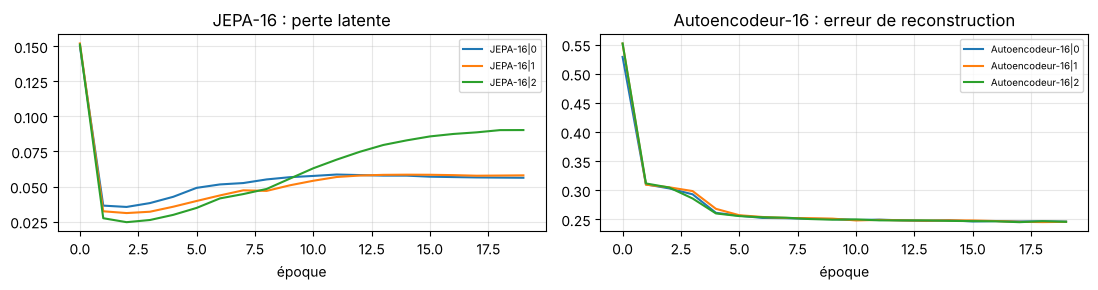

In [7]:
class Encoder(nn.Module):
    def __init__(self, d_in, d=96, L=WIN, depth=4, heads=4):
        super().__init__()
        self.proj = nn.Linear(d_in, d); self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.norm = nn.LayerNorm(d)
    def forward(self, x, mask=None):
        h = self.proj(x)
        if mask is not None: h = torch.where(mask[..., None], self.mask_tok.expand_as(h), h)
        return self.norm(self.tr(h + self.pos))

class Predictor(nn.Module):
    def __init__(self, d=96, L=WIN, depth=2, heads=4):
        super().__init__()
        self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02); self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.out = nn.Linear(d, d)
    def forward(self, ctx, mask):
        h = torch.where(mask[..., None], self.mask_tok.expand_as(ctx), ctx) + self.pos
        return self.out(self.tr(h))

def make_decoder():
    dec = Predictor(); dec.out = nn.Linear(96, D_TOK); return dec

def random_masks(B, rng, n_blocks=4, blen=6):
    m = np.zeros((B, WIN), bool)
    for i in range(B):
        for s in rng.integers(0, WIN - blen, n_blocks): m[i, s:s + blen] = True
    return torch.from_numpy(m)

ALL = MACH + FLOTTE
TOKT = {m: torch.from_numpy(TOK[m]) for m in ALL}
RUNT = {m: torch.from_numpy(RUN[m]) for m in MACH}
def batch_from(idx): return torch.stack([TOKT[ALL[mi]][s:s + WIN] for mi, s in idx])

def corpus(machines):
    out = []
    t_end = int((TRAIN_END - T0).total_seconds() // 60) // TOKM
    for m in machines:
        csr = np.r_[0, np.cumsum(RUN[m])]; starts = np.arange(0, t_end - WIN)
        ok = (csr[starts + WIN] - csr[starts]) * TOKM >= MIN_RUN
        out += [(ALL.index(m), s) for s in starts[ok]]
    return np.array(out)
PRE = {"4": corpus(MACH), "16": corpus(ALL)}
print({k: f"{len(v):,} fenêtres possibles" for k, v in PRE.items()})

def pretrain(kind, pre_idx, seed, epochs=EPOCHS, steps=STEPS_PER_EPOCH, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK)
    if kind == "jepa":
        head = Predictor(); tgt = Encoder(D_TOK); tgt.load_state_dict(enc.state_dict())
        for p in tgt.parameters(): p.requires_grad_(False)
    else:
        head = make_decoder()
    opt = torch.optim.AdamW(list(enc.parameters()) + list(head.parameters()), lr=5e-4, weight_decay=0.05)
    total = epochs * steps; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 5e-4, total_steps=total, pct_start=0.1)
    hist = []; step = 0
    for ep in range(epochs):
        tot = 0.0
        for _ in range(steps):
            x = batch_from(pre_idx[rng.integers(0, len(pre_idx), B)]); mask = random_masks(B, rng)
            if kind == "jepa":
                with torch.no_grad(): target = F.layer_norm(tgt(x), (96,))
                loss = F.smooth_l1_loss(head(enc(x, mask), mask)[mask], target[mask])
            else:
                loss = F.mse_loss(head(enc(x, mask), mask)[mask], x[mask])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0); opt.step(); sched.step()
            if kind == "jepa":
                mom = 0.996 + (1 - 0.996) * step / total
                with torch.no_grad():
                    for pt, pe in zip(tgt.parameters(), enc.parameters()): pt.mul_(mom).add_(pe.detach(), alpha=1 - mom)
            step += 1; tot += loss.item()
        hist.append(tot / steps)
        if ep % 5 == 4 or ep == epochs - 1: print(f"  {kind} graine {seed}, époque {ep + 1}/{epochs} : perte {hist[-1]:.4f}", flush=True)
    # pour JEPA, on garde l'encodeur cible (moyenne mobile), comme dans le notebook précédent
    return (tgt if kind == "jepa" else enc).state_dict(), hist

# Encodeurs : (nom, fichier de poids, clé dans le fichier, type, corpus)
ENCODERS = {
    "JEPA-4": (RES_4ANS / "jepa_seed{s}.pt", "tgt", "jepa", "4"),
    "Autoencodeur-4": (RES_4ANS / "autoencodeur_seed{s}.pt", "enc", "ae", "4"),
    "JEPA-16": (RES / "jepa16_seed{s}.pt", "enc", "jepa", "16"),
    "Autoencodeur-16": (RES / "autoencodeur16_seed{s}.pt", "enc", "ae", "16"),
}
STATES, HIST = {}, json.load(open(RES / "historiques.json")) if (RES / "historiques.json").exists() else {}
for name, (pattern, key, kind, corp) in ENCODERS.items():
    for s_ in SEEDS:
        path = Path(str(pattern).format(s=s_)); t1 = time.time()
        if corp == "4":                                  # poids du notebook précédent, jamais ré-entraînés ici
            STATES[(name, s_)] = torch.load(path)[key]; msg = "poids repris de F-JEPA_capteurs_4ans"
        elif path.exists() and not RECALCULER and torch.load(path).get("config") == CONFIG:
            STATES[(name, s_)] = torch.load(path)[key]; msg = "poids relus"
        else:
            st, h = pretrain(kind, PRE[corp], s_)
            torch.save({key: st, "config": CONFIG}, path); STATES[(name, s_)] = st; HIST[f"{name}|{s_}"] = h
            json.dump(HIST, open(RES / "historiques.json", "w")); msg = "pré-entraîné"
        print(f"{name:<16} graine {s_} : {msg} ({time.time() - t1:.0f} s)")

if HIST:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    for k_, h in HIST.items():
        ax[0 if k_.startswith("JEPA") else 1].plot(h, label=k_)
    ax[0].set_title("JEPA-16 : perte latente"); ax[1].set_title("Autoencodeur-16 : erreur de reconstruction")
    for a in ax: a.set_xlabel("époque"); a.legend(fontsize=7)
    plt.tight_layout(); plt.show()

## 7. Sondes sur l'encodeur gelé

Représentation d'une fenêtre : moyenne des sorties de l'encodeur sur la fenêtre, sur les tokens en marche et sur les 4 dernières heures (288 nombres), z-normalisée par machine et lissée sur 24 h. Sonde logistique (C choisi en validation) apprise sur le budget d'étiquettes. Le contrôle « aléatoire » est le même encodeur avec des poids aléatoires (même graine que dans le notebook précédent).

In [8]:
@torch.inference_mode()
def embed(state):
    enc = Encoder(D_TOK); enc.load_state_dict(state); enc.eval(); out = []
    idx = np.array([(ALL.index(m), e - WIN) for m, e in zip(S.machine, S.tok_end)])
    for i in range(0, len(idx), 512):
        ii = idx[i:i + 512]; z = enc(batch_from(ii))
        w = torch.stack([RUNT[ALL[mi]][s:s + WIN] for mi, s in ii])[..., None]
        out.append(torch.cat([z.mean(1), (z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1).numpy())
    return np.concatenate(out)

def probe_features(emb):
    Zz = zscore_per_machine(pd.DataFrame(emb, index=S.index), ref)
    return pd.concat([Zz, ewm_per_machine(Zz, 12).add_suffix("_l")], axis=1).loc[E.index].fillna(0).to_numpy()

for s_ in SEEDS:
    torch.manual_seed(1000 + s_); STATES[("Aléatoire", s_)] = Encoder(D_TOK).state_dict()
ENC_NAMES = ["Aléatoire", "JEPA-4", "Autoencodeur-4", "JEPA-16", "Autoencodeur-16"]
for name in ENC_NAMES:
    for s_ in SEEDS:
        t1 = time.time(); Zf = probe_features(embed(STATES[(name, s_)]))
        for L in BUDGETS:
            SCORES[(f"{name} sonde", L, s_)], _, _ = fit_select(lr_grid, Zf, TR[L])
        print(f"{name:<16} graine {s_} : sondes pour {len(BUDGETS)} budgets en {time.time() - t1:.0f} s")

Aléatoire        graine 0 : sondes pour 4 budgets en 130 s


Aléatoire        graine 1 : sondes pour 4 budgets en 125 s


Aléatoire        graine 2 : sondes pour 4 budgets en 130 s


JEPA-4           graine 0 : sondes pour 4 budgets en 124 s


JEPA-4           graine 1 : sondes pour 4 budgets en 129 s


...

JEPA-16          graine 1 : sondes pour 4 budgets en 132 s


JEPA-16          graine 2 : sondes pour 4 budgets en 111 s


Autoencodeur-16  graine 0 : sondes pour 4 budgets en 129 s


Autoencodeur-16  graine 1 : sondes pour 4 budgets en 130 s


Autoencodeur-16  graine 2 : sondes pour 4 budgets en 128 s


## 8. Fine-tuning

Même procédure que dans le notebook précédent : tête linéaire sur l'encodeur, tout est entraîné sur le budget d'étiquettes (6 époques de 150 lots, meilleure époque en validation), probabilités lissées sur 24 h. Faits pour les budgets de 2, 6 et 24 mois (le fine-tuning coûte ≈ 4 min par modèle). Les fine-tunings à 24 mois de l'aléatoire, de JEPA-4 et de l'autoencodeur-4 sont repris du notebook précédent (même code, même graine).

Les résultats sont enregistrés au fur et à mesure (`results_flotte/fine_tuning.pkl`) : une exécution interrompue reprend où elle s'était arrêtée.

Petite différence avec les sondes et le boosting, gardée pour rester identique au notebook précédent : les probabilités fine-tunées sont lissées sur les seules fenêtres évaluées, alors que les caractéristiques des sondes et du boosting sont lissées sur toutes les fenêtres. Vérifié à la relecture du protocole sur les fine-tunings du notebook précédent : cela coûte environ 0,007 d'AUC aux modèles fine-tunés face aux sondes et au boosting, et ne change rien entre modèles fine-tunés.

In [9]:
class Classifier(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = enc; self.head = nn.Sequential(nn.LayerNorm(192), nn.Linear(192, 1))
    def forward(self, x, w):
        z = self.enc(x)
        return self.head(torch.cat([(z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1))[:, 0]

E_IDX = np.array([(ALL.index(m), e - WIN) for m, e in zip(E.machine, E.tok_end)])
def batch_w(idx): return torch.stack([RUNT[ALL[mi]][s:s + WIN] for mi, s in idx])[..., None]
def smooth_rows(p, rows):
    return pd.Series(p, index=E.index[rows]).groupby(E.machine.to_numpy()[rows]).transform(lambda x: x.ewm(span=12).mean()).to_numpy()

@torch.inference_mode()
def predict_rows(model, rows, B=512):
    model.eval(); out = []
    for i in range(0, len(rows), B):
        idx = E_IDX[rows[i:i + B]]; out.append(model(batch_from(idx), batch_w(idx)).numpy())
    return np.concatenate(out)

def finetune(enc_state, seed, tr_mask, epochs=FT_EPOCHS, steps=150, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK)
    if enc_state is not None: enc.load_state_dict(enc_state)
    model = Classifier(enc)
    opt = torch.optim.AdamW([{"params": model.enc.parameters(), "lr": 2e-4}, {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    tr_rows, va_rows = np.flatnonzero(tr_mask), np.flatnonzero(va_m)
    yt_ = torch.tensor(yE, dtype=torch.float32); best = (-1, None, 0)
    for ep in range(epochs):
        model.train()
        for _ in range(steps):
            r_ = rng.choice(tr_rows, B); idx = E_IDX[r_]
            loss = F.binary_cross_entropy_with_logits(model(batch_from(idx), batch_w(idx)), yt_[r_])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc_v = roc_auc_score(yE[va_rows], smooth_rows(predict_rows(model, va_rows), va_rows))
        if auc_v > best[0]: best = (auc_v, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1]); all_rows = np.arange(len(E))
    return smooth_rows(predict_rows(model, all_rows), all_rows), best[0], best[2]

ft_file = RES / "fine_tuning.pkl"
FT = pickle.load(open(ft_file, "rb")) if ft_file.exists() and not RECALCULER else {}
if FT.get("_config") != CONFIG_FT: FT = {}            # réglages changés : on ne réutilise rien
FT["_config"] = CONFIG_FT
# reprise des fine-tunings à 24 mois du notebook précédent (aléatoire, JEPA-4, autoencodeur-4) : même code, 6 époques, tout l'entraînement
OLD = {"Aléatoire": ("scores_finetune.pkl", "Encodeur aléatoire fine-tuné"), "JEPA-4": ("scores_finetune.pkl", "JEPA fine-tuné"),
       "Autoencodeur-4": ("scores_finetune_autoencodeur.pkl", "Autoencodeur fine-tuné")}
if 24 in FT_BUDGETS and FT_EPOCHS == 6:
    assert TR[24].sum() == (E.split == "train").sum()
    for name, (fn, key) in OLD.items():
        old = pickle.load(open(RES_4ANS / fn, "rb"))
        for s_ in SEEDS:
            assert len(old[s_][key]) == len(E)
            FT.setdefault((name, 24, s_), (old[s_][key], np.nan, "repris"))
for L in FT_BUDGETS:
    for name in ENC_NAMES:
        for s_ in SEEDS:
            if (name, L, s_) in FT: continue
            t1 = time.time()
            p, a, ep_ = finetune(None if name == "Aléatoire" else STATES[(name, s_)], s_, TR[L])
            FT[(name, L, s_)] = (p, a, ep_); pickle.dump(FT, open(ft_file, "wb"))
            print(f"budget {L:>2} mois  {name:<16} graine {s_} : AUC validation {a:.3f} (époque {ep_}), {time.time() - t1:.0f} s", flush=True)
for k_, v_ in FT.items():
    if k_ == "_config": continue
    (name, L, s_), (p, a, ep_) = k_, v_
    if L in FT_BUDGETS and s_ in SEEDS: SCORES[(f"{name} fine-tuné", L, s_)] = p
print(f"fine-tuning terminé ({(time.time() - t_start) / 60:.0f} min écoulées)")
# récapitulatif de tous les fine-tunings (y compris ceux relus du cache) : AUC de validation et époque retenue
pd.DataFrame([dict(encodeur=k_[0], budget_mois=k_[1], graine=k_[2], auc_validation=v_[1], epoque=v_[2]) for k_, v_ in FT.items() if k_ != "_config"]
             ).pivot_table(index="encodeur", columns=["budget_mois", "graine"], values=["auc_validation"]).round(3)

fine-tuning terminé (33 min écoulées)


auc_validation                                                        
budget_mois                 2                    6                    24              
graine                       0      1      2      0      1      2      0      1      2
encodeur                                                                              
Aléatoire                0.578  0.523  0.506  0.619  0.593  0.545    NaN    NaN    NaN
Autoencodeur-16          0.485  0.490  0.492  0.626  0.562  0.580  0.674  0.674  0.673
Autoencodeur-4           0.493  0.528  0.487  0.626  0.567  0.580    NaN    NaN    NaN
JEPA-16                  0.518  0.537  0.515  0.586  0.590  0.581  0.661  0.687  0.668
JEPA-4                   0.561  0.564  0.517  0.606  0.604  0.608    NaN    NaN    NaN

## 9. Résultats sur le test (sept. 2025 → août 2026)

ROC-AUC de chaque méthode selon le budget d'étiquettes. Pour les réseaux : **ensemble** des 3 graines (moyenne des rangs) et AUC de chaque graine. Intervalle à 95 % par bootstrap par blocs (machine × semaine) pour l'ensemble.

In [10]:
Et = E[te_m]; yt = Et.y.to_numpy()
blocks = (Et.machine + "_" + Et.time.dt.strftime("%G-%V")).to_numpy()
ub = np.unique(blocks); bidx = {b: np.flatnonzero(blocks == b) for b in ub}
rngb = np.random.default_rng(0); BOOT = [np.concatenate([bidx[b] for b in rngb.choice(ub, len(ub))]) for _ in range(300)]
def rank(x): return pd.Series(x).rank(pct=True).to_numpy()
def auc_t(p): return roc_auc_score(yt, p[te_m])

methods = sorted({k[0] for k in SCORES})
rows = []
for meth in methods:
    for L in BUDGETS:
        seeds_ = [s_ for s_ in SEEDS if (meth, L, s_) in SCORES]
        if (meth, L, None) in SCORES: p = SCORES[(meth, L, None)]; per = []
        elif seeds_:
            p = np.mean([rank(SCORES[(meth, L, s_)]) for s_ in seeds_], 0); per = [auc_t(SCORES[(meth, L, s_)]) for s_ in seeds_]
        else: continue
        sc = p[te_m]; bs = [roc_auc_score(yt[i], sc[i]) for i in BOOT]
        rows.append(dict(methode=meth, budget_mois=L, roc_auc=roc_auc_score(yt, sc), ic95_bas=np.percentile(bs, 2.5), ic95_haut=np.percentile(bs, 97.5),
                         pr_auc=average_precision_score(yt, sc), par_graine=" / ".join(f"{x:.3f}" for x in per),
                         moyenne_graines=np.mean(per) if per else np.nan))
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(RES / "metriques_par_budget.csv", index=False)
TAB = RESULTS.pivot_table(index="methode", columns="budget_mois", values="roc_auc").round(3)
print(f"Test : {len(yt):,} fenêtres, {yt.mean():.1%} positives")
TAB.sort_values(BUDGETS[-1], ascending=False)

Test : 10,636 fenêtres, 20.1% positives


budget_mois,2,6,12,24
methode,,,,
JEPA-16 fine-tuné,0.505,0.597,NaN,0.751
JEPA-4 fine-tuné,0.544,0.636,NaN,0.748
Aléatoire fine-tuné,0.544,0.630,NaN,0.726
Logistique experts,0.504,0.724,0.719,0.716
Boosting experts,0.582,0.714,0.723,0.715
Autoencodeur-4 sonde,0.535,0.668,0.674,0.712
Autoencodeur-16 fine-tuné,0.526,0.612,NaN,0.706
Autoencodeur-4 fine-tuné,0.538,0.636,NaN,0.704
JEPA-4 sonde,0.554,0.607,0.660,0.685


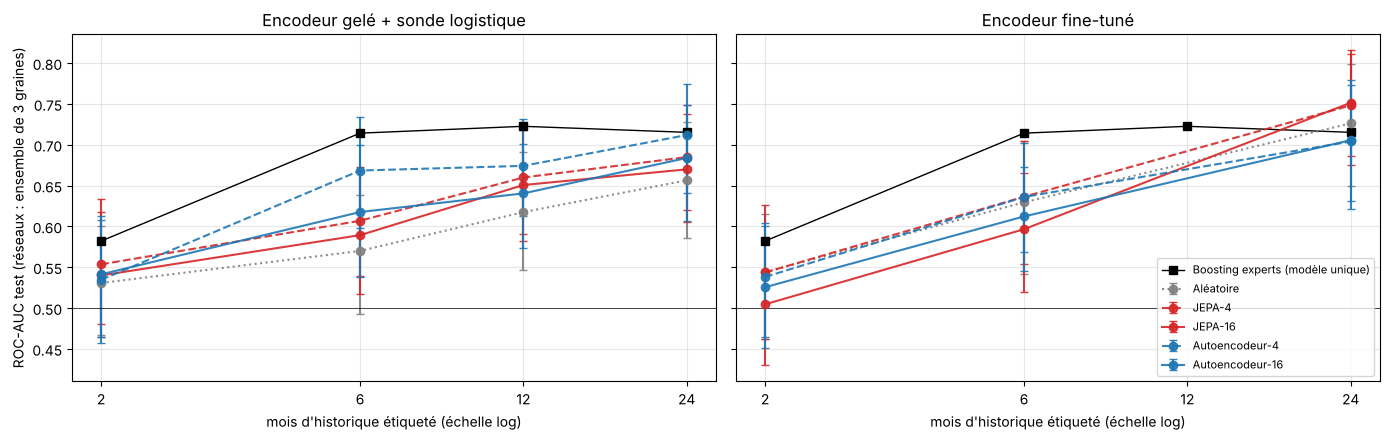

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
STY = {"Aléatoire": ("grey", ":"), "JEPA-4": ("C3", "--"), "JEPA-16": ("C3", "-"), "Autoencodeur-4": ("C0", "--"), "Autoencodeur-16": ("C0", "-")}
for ax, tete in zip(axes, ["sonde", "fine-tuné"]):
    for name, (c, ls) in STY.items():
        r_ = RESULTS[RESULTS.methode == f"{name} {tete}"].sort_values("budget_mois")
        if len(r_): ax.errorbar(r_.budget_mois, r_.roc_auc, yerr=[r_.roc_auc - r_.ic95_bas, r_.ic95_haut - r_.roc_auc], color=c, ls=ls, marker="o", capsize=3, label=name, alpha=0.9)
    r_ = RESULTS[RESULTS.methode == "Boosting experts"].sort_values("budget_mois")
    ax.plot(r_.budget_mois, r_.roc_auc, color="k", marker="s", lw=1, label="Boosting experts (modèle unique)")
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS); ax.set_xlabel("mois d'historique étiqueté (échelle log)")
    ax.set_title(f"Encodeur {'gelé + sonde logistique' if tete == 'sonde' else 'fine-tuné'}"); ax.axhline(0.5, color="k", lw=0.5)
axes[0].set_ylabel("ROC-AUC test (réseaux : ensemble de 3 graines)"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(RES / "courbe_budget_etiquettes.png", dpi=90); plt.show()

### 9.1 Écarts par graine

Ce qui compte pour conclure : l'écart **pour chaque graine**. À graine égale, deux modèles ont la même initialisation et les mêmes tirages de fine-tuning ; ils partagent aussi les mêmes lots et les mêmes masques de pré-entraînement quand ils ont le même corpus (JEPA-16 contre autoencodeur-16), mais pas entre 4 et 16 machines.

In [12]:
def ecarts(a, b, tete):
    rows = []
    for L in BUDGETS:
        d = [auc_t(SCORES[(f"{a} {tete}", L, s_)]) - auc_t(SCORES[(f"{b} {tete}", L, s_)]) for s_ in SEEDS
             if (f"{a} {tete}", L, s_) in SCORES and (f"{b} {tete}", L, s_) in SCORES]
        if d: rows.append(dict(comparaison=f"{a} − {b} ({tete})", budget_mois=L, moyenne=np.mean(d), par_graine=" / ".join(f"{x:+.3f}" for x in d),
                               graines_positives=f"{sum(x > 0 for x in d)}/{len(d)}"))
    return rows
EC = pd.DataFrame(sum([ecarts(a, b, t) for t in ["sonde", "fine-tuné"]
                       for a, b in [("JEPA-16", "Aléatoire"), ("JEPA-16", "JEPA-4"), ("JEPA-16", "Autoencodeur-16"), ("Autoencodeur-16", "Aléatoire"), ("Autoencodeur-16", "Autoencodeur-4")]], []))
EC.to_csv(RES / "ecarts_par_graine.csv", index=False)
EC.round(3)

,comparaison,budget_mois,moyenne,par_graine,graines_positives
0,JEPA-16 − Aléatoire (sonde),2,-0.000,+0.034 / -0.021 / -0.013,1/3
1,JEPA-16 − Aléatoire (sonde),6,0.018,+0.024 / +0.024 / +0.006,3/3
2,JEPA-16 − Aléatoire (sonde),12,0.024,+0.013 / +0.019 / +0.041,3/3
3,JEPA-16 − Aléatoire (sonde),24,0.005,+0.013 / -0.010 / +0.013,2/3
4,JEPA-16 − JEPA-4 (sonde),2,-0.015,+0.008 / -0.029 / -0.025,1/3
5,JEPA-16 − JEPA-4 (sonde),6,-0.006,+0.051 / -0.031 / -0.040,1/3
6,JEPA-16 − JEPA-4 (sonde),12,-0.004,+0.016 / +0.004 / -0.031,2/3
7,JEPA-16 − JEPA-4 (sonde),24,-0.009,+0.009 / -0.008 / -0.029,1/3
8,JEPA-16 − Autoencodeur-16 (sonde),2,-0.004,+0.028 / -0.053 / +0.012,2/3
9,JEPA-16 − Autoencodeur-16 (sonde),6,-0.027,-0.019 / -0.041 / -0.021,0/3


### 9.2 Par type de dégradation, au plus petit budget

ROC-AUC des fenêtres positives d'un type donné contre toutes les fenêtres négatives du test (ensemble des graines).

In [13]:
Lmin = min(FT_BUDGETS); neg = yt == 0; rows = []
for meth in ["Boosting experts", "Aléatoire fine-tuné", "JEPA-16 fine-tuné", "Autoencodeur-16 fine-tuné", "JEPA-16 sonde", "Autoencodeur-16 sonde", "Aléatoire sonde"]:
    if (meth, Lmin, None) in SCORES: p = SCORES[(meth, Lmin, None)]
    else: p = np.mean([rank(SCORES[(meth, Lmin, s_)]) for s_ in SEEDS], 0)
    sc = p[te_m]; row = {"methode": meth}
    for ft in ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"]:
        pos = (yt == 1) & (Et.type_suivant.to_numpy() == ft)
        row[ft] = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(neg.sum())], np.r_[sc[pos], sc[neg]]) if pos.sum() else np.nan
    rows.append(row)
print(f"Budget de {Lmin} mois d'étiquettes")
pd.DataFrame(rows).set_index("methode").round(3)

Budget de 2 mois d'étiquettes


,refroidissement,roulement,courroie,pneumatique,electrique
methode,,,,,
Boosting experts,0.455,0.926,0.621,0.487,0.544
Aléatoire fine-tuné,0.506,0.685,0.669,0.517,0.382
JEPA-16 fine-tuné,0.420,0.693,0.549,0.491,0.424
Autoencodeur-16 fine-tuné,0.542,0.718,0.532,0.457,0.439
JEPA-16 sonde,0.561,0.548,0.432,0.501,0.675
Autoencodeur-16 sonde,0.471,0.645,0.449,0.528,0.652
Aléatoire sonde,0.443,0.705,0.539,0.486,0.546


## 10. Hypothèses et conclusions

Hypothèses copiées mot pour mot de `flotte_non_etiquetee/LISEZMOI_FLOTTE.md`, écrites **avant** toute exécution des modèles (H8 a été rendue plus stricte à la relecture du protocole, toujours avant exécution), et confrontées ici sans les réécrire :
- **H6.** Pré-entraîner sur 16 machines au lieu de 4 améliore la sonde JEPA (ROC-AUC test), pour chaque graine, au budget de 24 mois.
- **H7.** Avec peu d'étiquettes (2 et 6 mois), JEPA-16 fine-tuné bat l'encodeur aléatoire fine-tuné pour chaque graine, et l'écart moyen sur 2 et 6 mois est plus grand qu'à 24 mois.
- **H8.** Avec peu d'étiquettes (2 et 6 mois), JEPA-16 fine-tuné bat le boosting expert à chacun des deux budgets : la moyenne des ROC-AUC des 3 graines (un modèle contre un modèle) dépasse celle du boosting. L'ensemble des 3 graines est rapporté en complément.
- **H9.** JEPA-16 contre autoencodeur-16 : pas d'hypothèse de sens ; on rapporte l'écart par graine.

In [14]:
assert {2, 6, 24} <= set(FT_BUDGETS) and 24 in BUDGETS, "H6 à H8 demandent les budgets de 2, 6 et 24 mois"
TOUTES = f"{len(SEEDS)}/{len(SEEDS)}"
def ec(a, b, tete, L):
    r_ = EC[(EC.comparaison == f"{a} − {b} ({tete})") & (EC.budget_mois == L)]
    assert len(r_) == 1, (a, b, tete, L)
    return r_.iloc[0]
def R(meth, L):
    r_ = RESULTS[(RESULTS.methode == meth) & (RESULTS.budget_mois == L)]
    assert len(r_) == 1, (meth, L)
    return r_.iloc[0]

r6 = ec("JEPA-16", "JEPA-4", "sonde", 24)
print(f"H6 : sonde JEPA-16 − JEPA-4 à 24 mois = {r6.moyenne:+.3f} (par graine {r6.par_graine}) -> {'confirmée' if r6.graines_positives == TOUTES else 'non confirmée'}")
ok7 = True; gaps = []
for L in (2, 6):
    r7 = ec("JEPA-16", "Aléatoire", "fine-tuné", L); ok7 &= r7.graines_positives == TOUTES; gaps.append(r7.moyenne)
    print(f"     fine-tuné JEPA-16 − aléatoire à {L} mois = {r7.moyenne:+.3f} (par graine {r7.par_graine})")
r24 = ec("JEPA-16", "Aléatoire", "fine-tuné", 24); small = np.mean(gaps); ok7 &= small > r24.moyenne
print(f"H7 : écart moyen à 2 et 6 mois {small:+.3f} contre {r24.moyenne:+.3f} à 24 mois (par graine {r24.par_graine}) -> {'confirmée' if ok7 else 'non confirmée'}")
ok8 = True
for L in (2, 6):
    j_, b_ = R("JEPA-16 fine-tuné", L), R("Boosting experts", L); ok8 &= j_.moyenne_graines > b_.roc_auc
    print(f"     {L} mois : JEPA-16 fine-tuné moyenne des graines {j_.moyenne_graines:.3f} (graines {j_.par_graine} ; ensemble {j_.roc_auc:.3f} [{j_.ic95_bas:.2f} ; {j_.ic95_haut:.2f}])"
          f" contre boosting {b_.roc_auc:.3f} [{b_.ic95_bas:.2f} ; {b_.ic95_haut:.2f}]")
print(f"H8 : -> {'confirmée' if ok8 else 'non confirmée'}")
for tete in ["sonde", "fine-tuné"]:
    print(f"H9 ({tete}) : " + " ; ".join(f"{L} mois {ec('JEPA-16', 'Autoencodeur-16', tete, L).moyenne:+.3f} ({ec('JEPA-16', 'Autoencodeur-16', tete, L).par_graine})"
                                     for L in (BUDGETS if tete == "sonde" else FT_BUDGETS)))
print(f"\nDurée totale : {(time.time() - t_start) / 60:.0f} min")

H6 : sonde JEPA-16 − JEPA-4 à 24 mois = -0.009 (par graine +0.009 / -0.008 / -0.029) -> non confirmée
     fine-tuné JEPA-16 − aléatoire à 2 mois = -0.033 (par graine -0.077 / -0.006 / -0.015)
     fine-tuné JEPA-16 − aléatoire à 6 mois = -0.036 (par graine -0.073 / -0.017 / -0.018)
H7 : écart moyen à 2 et 6 mois -0.034 contre +0.003 à 24 mois (par graine +0.038 / -0.015 / -0.012) -> non confirmée
     2 mois : JEPA-16 fine-tuné moyenne des graines 0.502 (graines 0.499 / 0.499 / 0.509 ; ensemble 0.505 [0.43 ; 0.58]) contre boosting 0.582 [0.51 ; 0.66]
     6 mois : JEPA-16 fine-tuné moyenne des graines 0.580 (graines 0.574 / 0.578 / 0.589 ; ensemble 0.597 [0.52 ; 0.66]) contre boosting 0.714 [0.63 ; 0.78]
H8 : -> non confirmée
H9 (sonde) : 2 mois -0.004 (+0.028 / -0.053 / +0.012) ; 6 mois -0.027 (-0.019 / -0.041 / -0.021) ; 12 mois +0.004 (+0.017 / +0.017 / -0.022) ; 24 mois -0.018 (-0.023 / +0.013 / -0.043)
H9 (fine-tuné) : 2 mois -0.017 (-0.002 / -0.044 / -0.005) ; 6 mois -0.018 (-0.

### 10.1 Conclusions (rédigées après l'exécution, données SYNTHÉTIQUES)

**Réponse courte : sur ces données simulées et à calcul égal, 12 machines de plus sans étiquettes n'ont pas amélioré le pré-entraînement.** H6, H7 et H8 ne sont pas confirmées. Avec peu d'étiquettes, JEPA-16 fine-tuné fait même un peu moins bien que l'encodeur aléatoire fine-tuné, pour les 3 graines ; en sonde sur l'encodeur gelé, il fait un peu mieux que l'aléatoire à 6 et 12 mois (+0,018 et +0,024, 3 graines sur 3), sans approcher les caractéristiques expertes.

| Hypothèse | Résultat |
|---|---|
| **H6** 16 machines > 4 machines (sonde JEPA, 24 mois) | **Non confirmée** : −0,009 (+0,009 / −0,008 / −0,029). Pour l'autoencodeur, la sonde AE-16 est sous AE-4 en moyenne à 6, 12 et 24 mois (−0,038, −0,030, −0,028). |
| **H7** JEPA-16 fine-tuné > aléatoire avec peu d'étiquettes | **Non confirmée** : écart négatif pour les 3 graines à 2 mois (−0,077 / −0,006 / −0,015, moyenne −0,033) et à 6 mois (−0,073 / −0,017 / −0,018, moyenne −0,036), surtout porté par la graine 0 ; +0,003 à 24 mois. |
| **H8** JEPA-16 fine-tuné > boosting expert avec peu d'étiquettes | **Non confirmée** : 0,50 contre 0,58 [0,51 ; 0,66] à 2 mois, deux scores proches du hasard ; 0,58 contre 0,71 [0,63 ; 0,78] à 6 mois, où les 3 graines (0,574 à 0,589) sont sous la borne basse de l'intervalle du boosting (moyenne des graines contre boosting). En ensemble : 0,505 et 0,597. |
| **H9** JEPA-16 contre AE-16 (pas de sens attendu) | Sonde : −0,004 à 2 mois, −0,027 à 6 mois (3 graines sur 3 pour l'AE), +0,004 à 12 mois, −0,018 à 24 mois (2 graines sur 3 pour l'AE). Fine-tuné : −0,017 à 2 mois, −0,018 à 6 mois, +0,030 à 24 mois (3 graines sur 3 pour JEPA, comme dans le notebook précédent). |

**Incertitude.** 3 graines seulement et un seul jeu de test (10 636 fenêtres, un an, 4 machines). Les intervalles à 95 % des ROC-AUC ont une demi-largeur de 0,06 à 0,09, bien plus que les écarts de H6, H7 et H9 (0,003 à 0,036). Aucun intervalle n'a été calculé sur les écarts eux-mêmes : seul leur signe graine par graine est rapporté, et 3 graines sur 3 du même signe arrive par hasard une fois sur huit dans un sens donné. Seuls les écarts d'environ 0,1 avec le boosting à 6 mois (H8) dépassent nettement cette incertitude.

**Ce que cela montre**
1. **Quatre fois plus de données non étiquetées n'ont pas donné de meilleures représentations.** Le corpus de pré-entraînement passe de 204 000 à 816 000 fenêtres (la flotte contient 200 pannes ou ralentissements sur la période, jamais étiquetés), avec le même nombre de pas : chaque fenêtre est vue environ 4 fois moins souvent, et l'essai ne dit pas ce que donnerait un pré-entraînement plus long. Les 12 machines sortent du même simulateur que M1 à M4, un cas favorable au pré-entraînement, et pourtant sans effet. *Interprétation, non testée ici* : l'objectif de pré-entraînement apprend surtout ce qui est prévisible dans un token de 15 min (planning de production, charge, température de l'atelier), pas le ralentissement d'une constante de temps qui signe une dégradation.
2. **À 6 mois d'étiquettes, les caractéristiques expertes gagnent.** Avec 18 événements, le boosting atteint déjà 0,71, son niveau à 24 mois. Les réseaux, pré-entraînés ou non, sondes comme fine-tuning, restent entre 0,56 et 0,64 en moyenne des graines (0,53 à 0,66 graine par graine). L'écart est net pour JEPA-16 fine-tuné ; il ne l'est pas pour le meilleur réseau, la sonde autoencodeur-4 (0,67 [0,60 ; 0,73] en ensemble). Les meilleurs réseaux ont besoin des 2 ans d'étiquettes pour arriver à 0,71 en moyenne des graines.
3. **À 2 mois, personne ne prédit vraiment** (toutes les méthodes entre 0,50 et 0,58). Ces 2 mois ne contiennent que 7 événements étiquetés et aucune fenêtre positive de refroidissement ni de pneumatique, alors que ces deux types font près de la moitié des positifs du test. Cela n'explique pas tout : même sur les types présents, les réseaux restent faibles (section 9.2), et seul le boosting reconnaît bien le roulement (0,93).
4. **À 24 mois, le léger avantage des meilleurs réseaux sur le boosting tient à l'ensemble des 3 graines** : JEPA-16 et JEPA-4 fine-tunés font 0,75 [0,69 ; 0,81] et 0,75 [0,68 ; 0,82] contre 0,72 [0,62 ; 0,80] pour le boosting, des intervalles qui se recouvrent largement. L'encodeur aléatoire fine-tuné fait 0,73 et les autres réseaux restent sous le boosting. Un réseau seul fait 0,71 en moyenne des graines, comme le boosting.

Le petit handicap des modèles fine-tunés lié au lissage (environ 0,007, section 8) ne change aucun de ces verdicts. Calcul complet : environ 5 h sur 4 cœurs CPU (6 pré-entraînements d'environ 20 min, 36 fine-tunings de 3 à 4 min). Cette version du notebook relit les poids et tous les fine-tunings enregistrés (`results_flotte/`), d'où « poids relus » en section 6 et environ 40 min d'exécution ; les courbes de perte viennent de `results_flotte/historiques.json`.

**Piste suivante** : plutôt que plus de données, changer ce que le pré-entraînement doit prédire (par exemple un contexte de plusieurs jours, pour que la dérive d'une dynamique devienne la chose à prédire), ou vérifier d'abord qu'un pré-entraînement 4 fois plus long sur la flotte ne change rien. Et refaire l'essai sur de vrais capteurs dès qu'il y en aura.